<a href="https://colab.research.google.com/github/Nilamsari01/Pengolahan_Citra_Digital/blob/main/Tugas7_Nilam_Sari_F1G124046_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
!apt-get -qq install -y tesseract-ocr
!pip -q install pytesseract opencv-python

Saving gambar5.jpg to gambar5 (1).jpg
=== IJAZAH AWAL === (636, 450)


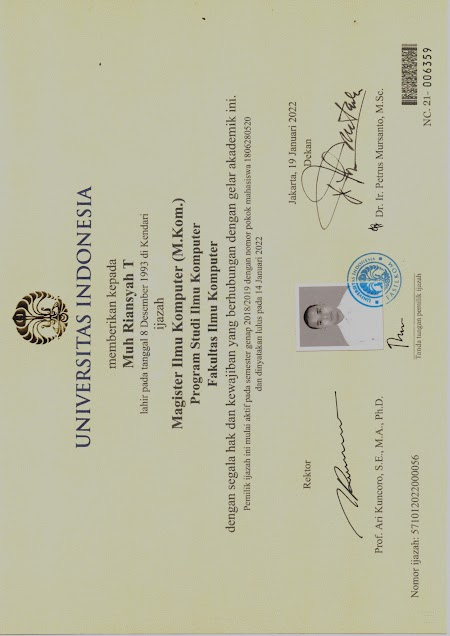

In [9]:
import os, re, random
from collections import Counter
import cv2, numpy as np, pytesseract
from google.colab import files
from google.colab.patches import cv2_imshow

up = files.upload()                      # pilih gambar5.jpg
IMAGE_PATH = list(up.keys())[0]
raw = cv2.imread(IMAGE_PATH)
print("=== IJAZAH AWAL ===", raw.shape[:2])
cv2_imshow(raw)

In [10]:
# ================= CONFIG =================
GT_NOMOR = "571012022000056"        # ground truth nomor ijazah (untuk menghitung CER)
ROTATION = "auto"                   # "auto" atau 0 / 90 / 180 / 270 (derajat searah jarum jam)

# ROI = (x1, y1, x2, y2) dalam pecahan 0-1 dari ukuran citra SETELAH dirotasi tegak
ROI_NUMBER = (0.155, 0.885, 0.300, 0.955)                     # "571012022000056"
ROI_SIGS = {"REKTOR": (0.14, 0.70, 0.41, 0.81),               # tanda tangan Rektor
            "DEKAN":  (0.64, 0.70, 0.90, 0.82)}               # tanda tangan Dekan
DIGIT_MIN, DIGIT_MAX = 12, 18
WHITELIST = "0123456789"
SIG_MIN_INK, SIG_MAX_INK = 0.004, 0.35
SIG_MIN_BBOX_W, SIG_MIN_AREA = 0.30, 0.005

# ================= UTIL =================
def crop_roi(img, roi):
    h, w = img.shape[:2]; x1, y1, x2, y2 = roi
    return img[int(y1*h):int(y2*h), int(x1*w):int(x2*w)]

def levenshtein(a, b):
    prev = list(range(len(b)+1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j]+1, cur[j-1]+1, prev[j-1]+(ca != cb)))
        prev = cur
    return prev[-1]

def cer(ref, hyp):                  # CER = (S + D + I) / N
    return levenshtein(ref, hyp) / max(1, len(ref))

# ================= ROTASI =================
_ROT = {0: None, 90: cv2.ROTATE_90_CLOCKWISE, 180: cv2.ROTATE_180, 270: cv2.ROTATE_90_COUNTERCLOCKWISE}
def rotate(img, deg):
    return img if _ROT[deg] is None else cv2.rotate(img, _ROT[deg])

def auto_rotation(img):
    """Coba 4 orientasi, pilih yang OCR-nya paling banyak menemukan kata yang terbaca."""
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    best, best_s = 0, -1
    for deg in (0, 90, 180, 270):
        r = cv2.resize(rotate(g, deg), None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
        d = pytesseract.image_to_data(r, config="--psm 6", output_type=pytesseract.Output.DICT)
        s = sum(float(c) for t, c in zip(d["text"], d["conf"]) if len(t.strip()) >= 4 and float(c) > 0)
        if s > best_s: best, best_s = deg, s
    return best

# ================= PREPROCESSING =================
def to_gray(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img

def enhance_global(gray):
    """Contrast stretching persentil (tanpa smoothing agar digit kecil tidak kabur)."""
    lo, hi = np.percentile(gray, (1, 99))
    return np.clip((gray.astype(np.float32)-lo)*255.0/max(hi-lo, 1), 0, 255).astype(np.uint8)

def _up(g, f=4):  return cv2.resize(g, None, fx=f, fy=f, interpolation=cv2.INTER_CUBIC)
def _pad(g):      return cv2.copyMakeBorder(g, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255)
def _clahe(g):    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
def _otsu(g):     return cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

# --- 9 metode enhancement area nomor (dibandingkan lewat CER) ---
def enh_gray(r):     return _pad(_up(r))                                   # baseline
def enh_hist_eq(r):  return _pad(cv2.equalizeHist(_up(r)))
def enh_clahe(r):    return _pad(_clahe(_up(r)))
def enh_unsharp(r):
    g = _up(r); return _pad(cv2.addWeighted(g, 1.8, cv2.GaussianBlur(g, (0, 0), 3), -0.8, 0))
def enh_bilateral_clahe(r): return _pad(_clahe(cv2.bilateralFilter(_up(r), 9, 60, 60)))
def enh_otsu(r):     return _pad(_otsu(cv2.GaussianBlur(_up(r), (5, 5), 0)))
def enh_adaptive(r):
    g = cv2.GaussianBlur(_up(r), (5, 5), 0)
    return _pad(cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 15))
def enh_clahe_otsu(r): return _pad(_otsu(cv2.GaussianBlur(_clahe(_up(r)), (5, 5), 0)))
def enh_bgnorm_otsu(r):
    g = _up(r); bg = cv2.GaussianBlur(g, (0, 0), 25)
    return _pad(_otsu(cv2.GaussianBlur(cv2.divide(g, bg, scale=255), (3, 3), 0)))

ENHANCERS = {"gray": enh_gray, "hist_eq": enh_hist_eq, "clahe": enh_clahe, "unsharp": enh_unsharp,
             "bilateral_clahe": enh_bilateral_clahe, "otsu": enh_otsu, "adaptive": enh_adaptive,
             "clahe_otsu": enh_clahe_otsu, "bgnorm_otsu": enh_bgnorm_otsu}
DEFAULT_ENHANCER = "otsu"           # ganti sesuai hasil evaluasi CER (Sel 7)

# ================= OCR =================
def parse_number(raw):
    s = re.sub(r"[^0-9]", "", raw)
    m = re.search(rf"\d{{{DIGIT_MIN},{DIGIT_MAX}}}", s)
    return m.group(0) if m else None

def read_number(img, scales=(1.0, 0.8, 1.25)):
    """OCR multi-skala + voting: ambil bacaan yang paling sering muncul."""
    cands, first = [], ""
    for sc in scales:
        im = img if sc == 1.0 else cv2.resize(img, None, fx=sc, fy=sc, interpolation=cv2.INTER_CUBIC)
        cfg = f"--oem 3 --psm 7 -c tessedit_char_whitelist={WHITELIST}"
        try:
            raw_txt = pytesseract.image_to_string(im, config=cfg).strip()
        except pytesseract.TesseractError:
            continue
        first = first or raw_txt
        p = parse_number(raw_txt)
        if p: cands.append(p)
    if cands:
        cnt = Counter(cands)
        best = max(cnt.items(), key=lambda kv: (kv[1], -abs(len(kv[0]) - 15)))[0]
        return best, first
    return (re.sub(r"[^0-9]", "", first) or "NOT_FOUND"), first

# ================= DETEKSI TANDA TANGAN =================
def detect_signature(roi_gray):
    h0, w0 = roi_gray.shape
    m = max(2, int(0.03*min(h0, w0)))                   # buang tepi ROI
    roi = roi_gray[m:h0-m, m:w0-m]; h, w = roi.shape
    # 1) Enhancement: normalisasi pencahayaan
    bg = cv2.GaussianBlur(roi, (0, 0), sigmaX=max(h, w)/8)
    norm = cv2.medianBlur(cv2.divide(roi, bg, scale=255), 3)
    # 2) Thresholding Otsu (dilewati jika area seragam = tidak ada tinta)
    contrast = 255 - np.percentile(norm, 0.5)
    if contrast < 50:
        binary = np.zeros_like(norm)
    else:
        t, _ = cv2.threshold(norm, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        binary = (norm < t).astype(np.uint8) * 255
    # 3) Morfologi: hapus bintik (opening), sambungkan goresan putus (closing)
    clean = cv2.morphologyEx(binary, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    k = max(5, int(0.04*w)) | 1
    morph = cv2.morphologyEx(clean, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    # 4) Analisis komponen terhubung -> ukur sebaran seluruh goresan
    n, _, stats, _ = cv2.connectedComponentsWithStats(morph, connectivity=8)
    min_a = max(6, 0.0008*h*w)
    comps = [stats[i] for i in range(1, n) if stats[i][4] >= min_a]
    ink = np.count_nonzero(clean) / (h*w)
    if comps:
        x1 = min(c[0] for c in comps); x2 = max(c[0]+c[2] for c in comps)
        y1 = min(c[1] for c in comps); y2 = max(c[1]+c[3] for c in comps)
        bbox_w, bbox_h = (x2-x1)/w, (y2-y1)/h
        area_r = sum(c[4] for c in comps) / (h*w)
    else:
        bbox_w = bbox_h = area_r = 0.0
    present = bool(comps and SIG_MIN_INK <= ink <= SIG_MAX_INK
                   and bbox_w >= SIG_MIN_BBOX_W and bbox_h >= 0.2 and area_r >= SIG_MIN_AREA)
    return {"present": present, "ink_ratio": round(float(ink), 4), "bbox_w": round(float(bbox_w), 3),
            "bbox_h": round(float(bbox_h), 3), "area": round(float(area_r), 4),
            "roi": roi, "binary": binary, "morphology": morph}

# ================= PIPELINE =================
def preprocess(img_bgr):
    return enhance_global(to_gray(img_bgr))

def verify_array(img_bgr, enhancer=DEFAULT_ENHANCER):
    enh = preprocess(img_bgr)
    number, _ = read_number(ENHANCERS[enhancer](crop_roi(enh, ROI_NUMBER)))
    sigs = {k: detect_signature(crop_roi(enh, r)) for k, r in ROI_SIGS.items()}
    return number, sigs

def verify(img_bgr, enhancer=DEFAULT_ENHANCER, show=True):
    enh = preprocess(img_bgr)
    num_proc = ENHANCERS[enhancer](crop_roi(enh, ROI_NUMBER))
    number, raw_txt = read_number(num_proc)
    sigs = {k: detect_signature(crop_roi(enh, r)) for k, r in ROI_SIGS.items()}

    print(f"Nomor Ijazah : {number}")
    for k, v in sigs.items():
        print(f"Tanda Tangan {k:7s}: {'PRESENT' if v['present'] else 'ABSENT'}")
    print(f"Tanda Tangan : {'PRESENT' if all(v['present'] for v in sigs.values()) else 'ABSENT'}  (semua penanda tangan)")

    if show:
        vis = img_bgr.copy(); H, W = vis.shape[:2]
        for roi, col in [(ROI_NUMBER, (0, 200, 0))] + [(r, (255, 0, 0)) for r in ROI_SIGS.values()]:
            cv2.rectangle(vis, (int(roi[0]*W), int(roi[1]*H)), (int(roi[2]*W), int(roi[3]*H)), col, 2)
        print("\n[1] Gray + enhancement global + ROI (hijau=nomor, biru=TTD)"); cv2_imshow(vis)
        print(f"[2] Area nomor setelah enhancement '{enhancer}'");              cv2_imshow(num_proc)
        for k, v in sigs.items():
            print(f"[3] TTD {k}: ROI -> threshold -> morfologi")
            cv2_imshow(np.hstack([cv2.resize(x, (330, 100)) for x in (v['roi'], v['binary'], v['morphology'])]))
            print("    metrik:", {a: b for a, b in v.items() if a not in ('roi', 'binary', 'morphology')})
    return number, sigs
print("Fungsi siap.")

Fungsi siap.


Terdeteksi perlu diputar 90° searah jarum jam
=== IJAZAH SETELAH ROTASI (tegak) === (450, 636)


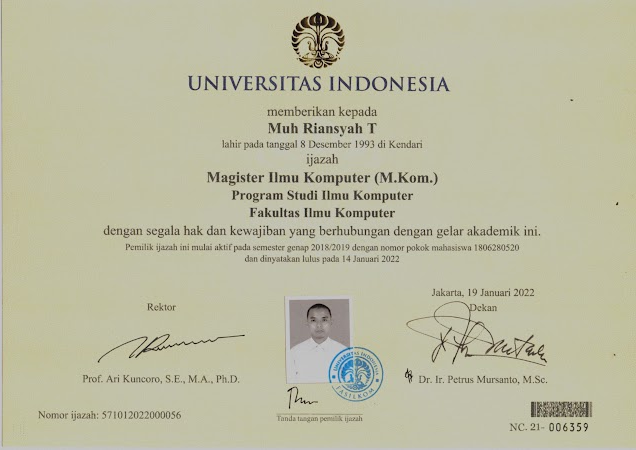

True

In [11]:
deg = auto_rotation(raw) if ROTATION == "auto" else ROTATION
print(f"Terdeteksi perlu diputar {deg}° searah jarum jam")
img = rotate(raw, deg)
print("=== IJAZAH SETELAH ROTASI (tegak) ===", img.shape[:2])
cv2_imshow(img)
cv2.imwrite("ijazah_001.jpg", img)

Nomor Ijazah : 571012022000056
Tanda Tangan REKTOR : PRESENT
Tanda Tangan DEKAN  : PRESENT
Tanda Tangan : PRESENT  (semua penanda tangan)

[1] Gray + enhancement global + ROI (hijau=nomor, biru=TTD)


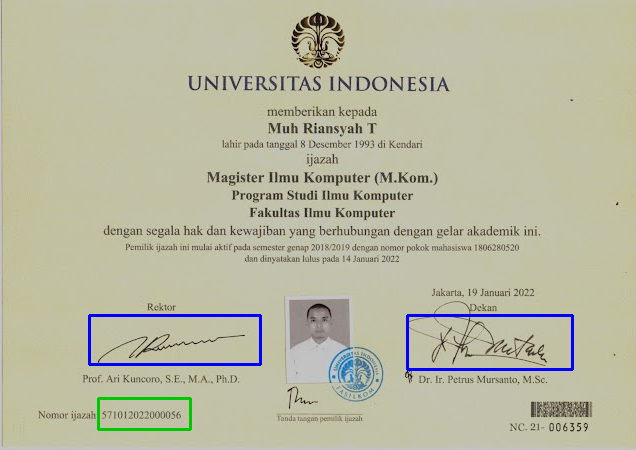

[2] Area nomor setelah enhancement 'otsu'


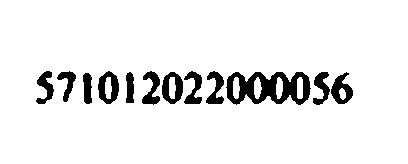

[3] TTD REKTOR: ROI -> threshold -> morfologi


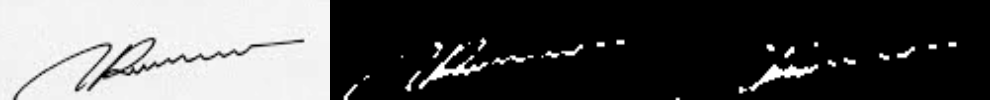

    metrik: {'present': True, 'ink_ratio': 0.0266, 'bbox_w': 0.659, 'bbox_h': 0.511, 'area': 0.0293}
[3] TTD DEKAN: ROI -> threshold -> morfologi


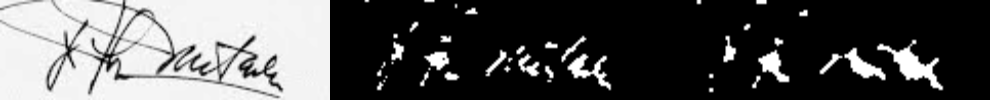

    metrik: {'present': True, 'ink_ratio': 0.0532, 'bbox_w': 0.665, 'bbox_h': 0.9, 'area': 0.0738}


('571012022000056',
 {'REKTOR': {'present': True,
   'ink_ratio': 0.0266,
   'bbox_w': 0.659,
   'bbox_h': 0.511,
   'area': 0.0293,
   'roi': array([[241, 243, 243, ..., 241, 241, 241],
          [241, 243, 243, ..., 247, 247, 247],
          [241, 243, 243, ..., 243, 243, 243],
          ...,
          [241, 253, 243, ..., 245, 245, 245],
          [243, 249, 243, ..., 243, 243, 243],
          [243, 247, 237, ..., 243, 243, 243]], dtype=uint8),
   'binary': array([[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]], dtype=uint8),
   'morphology': array([[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)},
  'DEKAN': {'present': True,
   'ink_ratio'

In [12]:
verify(img, enhancer=DEFAULT_ENHANCER, show=True)

In [13]:
blank = img.copy(); H, W = blank.shape[:2]
for r in ROI_SIGS.values():
    x1, y1, x2, y2 = int(r[0]*W), int(r[1]*H), int(r[2]*W), int(r[3]*H)
    blank[y1:y2, x1:x2] = np.median(blank[y1:y2, x1:x2].reshape(-1, 3), axis=0)
print("=== Simulasi ijazah TANPA tanda tangan ===")
verify(blank, show=False)

=== Simulasi ijazah TANPA tanda tangan ===
Nomor Ijazah : 571012022000056
Tanda Tangan REKTOR : ABSENT
Tanda Tangan DEKAN  : ABSENT
Tanda Tangan : ABSENT  (semua penanda tangan)


('571012022000056',
 {'REKTOR': {'present': False,
   'ink_ratio': 0.0,
   'bbox_w': 0.0,
   'bbox_h': 0.0,
   'area': 0.0,
   'roi': array([[244, 244, 244, ..., 244, 244, 244],
          [244, 244, 244, ..., 244, 244, 244],
          [244, 244, 244, ..., 244, 244, 244],
          ...,
          [244, 244, 244, ..., 244, 244, 244],
          [244, 244, 244, ..., 244, 244, 244],
          [244, 244, 244, ..., 244, 244, 244]], dtype=uint8),
   'binary': array([[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]], dtype=uint8),
   'morphology': array([[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)},
  'DEKAN': {'present': False,
   'ink_ratio': 0.0,
 

In [14]:
# Satu citra bersih saja kurang adil (banyak metode sama-sama CER 0).
# Maka dibuat 14 variasi citra yang didegradasi (cahaya tak merata, blur, noise, JPEG).
def degrade(im, rng):
    H, W = im.shape[:2]
    f = rng.uniform(0.9, 1.0)
    out = cv2.resize(cv2.resize(im, None, fx=f, fy=f, interpolation=cv2.INTER_AREA), (W, H))
    gx = np.linspace(rng.uniform(0.7, 1.0), rng.uniform(0.9, 1.05), W)[None, :, None]
    gy = np.linspace(rng.uniform(0.75, 1.0), rng.uniform(0.7, 1.0), H)[:, None, None]
    out = out.astype(np.float32) * gx * gy
    k = rng.choice([1, 1, 3])
    if k > 1: out = cv2.GaussianBlur(out, (k, k), 0)
    out += np.random.default_rng(rng.randint(0, 99999)).normal(0, rng.uniform(2, 8), out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    _, enc = cv2.imencode(".jpg", out, [cv2.IMWRITE_JPEG_QUALITY, rng.randint(70, 95)])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR)

rng = random.Random(7)
data = [img] + [degrade(img, rng) for _ in range(14)]     # 1 asli + 14 degradasi
print(f"Jumlah citra uji: {len(data)} (proses beberapa menit)\n")

results = {}
for name in ENHANCERS:
    cers, exact = [], 0
    for d in data:
        n, _ = verify_array(d, name)
        cers.append(cer(GT_NOMOR, n)); exact += (n == GT_NOMOR)
    results[name] = (sum(cers)/len(cers), exact/len(data), cer(GT_NOMOR, verify_array(img, name)[0]))
    print(f"selesai: {name}")

print(f"\n{'Rank':<5}{'Enhancement':<17}{'Mean CER':<10}{'Exact match':<13}{'CER citra asli'}")
for i, (n, (c, e, c0)) in enumerate(sorted(results.items(), key=lambda x: x[1][0]), 1):
    print(f"{i:<5}{n:<17}{c:<10.4f}{e:<13.0%}{c0:.3f}{'   <- TERBAIK' if i == 1 else ''}")

Jumlah citra uji: 15 (proses beberapa menit)

selesai: gray
selesai: hist_eq
selesai: clahe
selesai: unsharp
selesai: bilateral_clahe
selesai: otsu
selesai: adaptive
selesai: clahe_otsu
selesai: bgnorm_otsu

Rank Enhancement      Mean CER  Exact match  CER citra asli
1    otsu             0.2356    13%          0.000   <- TERBAIK
2    bgnorm_otsu      0.2711    7%           0.000
3    bilateral_clahe  0.5333    13%          0.000
4    clahe            0.5600    13%          0.000
5    clahe_otsu       0.5956    7%           0.000
6    adaptive         0.6044    7%           0.067
7    gray             0.6133    7%           0.000
8    unsharp          0.6533    13%          0.000
9    hist_eq          0.9556    0%           0.867


gray             -> 571012022000056   CER=0.000


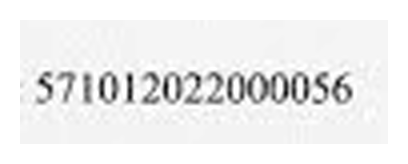

hist_eq          -> 06   CER=0.867


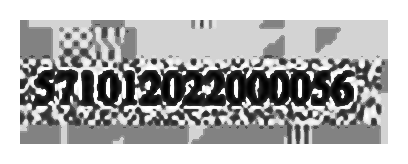

clahe            -> 571012022000056   CER=0.000


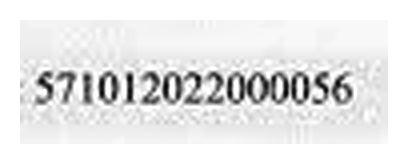

unsharp          -> 571012022000056   CER=0.000


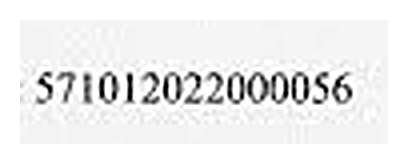

bilateral_clahe  -> 571012022000056   CER=0.000


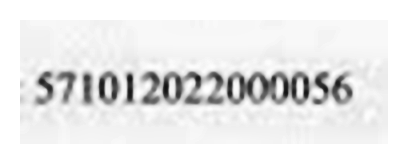

otsu             -> 571012022000056   CER=0.000


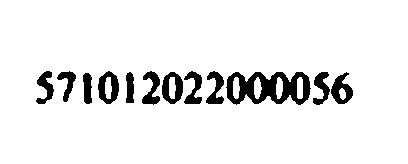

adaptive         -> 71012022000056   CER=0.067


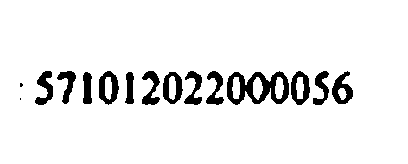

clahe_otsu       -> 571012022000056   CER=0.000


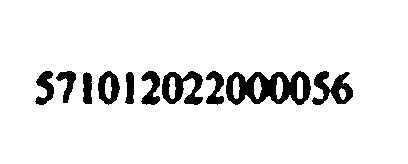

bgnorm_otsu      -> 571012022000056   CER=0.000


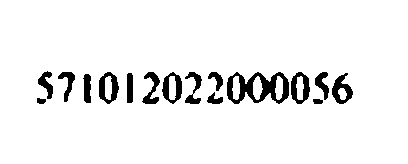

In [15]:
enh = preprocess(img)
roi_num = crop_roi(enh, ROI_NUMBER)
for name, fn in ENHANCERS.items():
    out = fn(roi_num)
    n, _ = read_number(out)
    print(f"{name:16s} -> {n}   CER={cer(GT_NOMOR, n):.3f}")
    cv2_imshow(out)